In [1]:
# Can change any data to normal distribution
# Special Case of this transform is log transform

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import scipy.stats as stats

In [4]:
from sklearn.model_selection import train_test_split as tts
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer

In [5]:
df = pd.read_csv('concrete_data.csv')

In [6]:
df.head(3)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27


In [7]:
df.shape

(1030, 9)

In [8]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [9]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [10]:
df.head(2)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89


In [11]:
X=df.drop(columns=['Strength'])

In [12]:
y=df['Strength']

In [13]:
X_train,X_test,y_train,y_test=tts(X,y,test_size=0.2,random_state=42)

In [14]:
lr=LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
r2_score(y_test,y_pred)

0.6275531792314848

In [15]:
np.mean(cross_val_score(lr,X,y,scoring='r2'))

0.46099404916628683

<Figure size 1400x400 with 0 Axes>

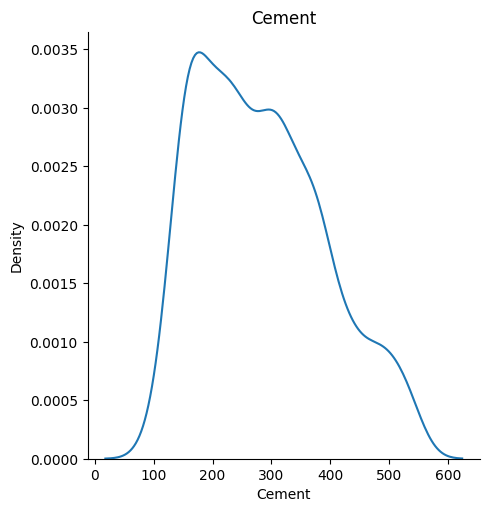

<Figure size 1400x400 with 0 Axes>

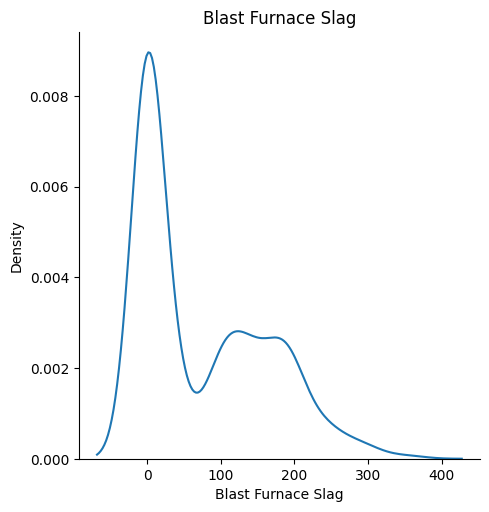

<Figure size 1400x400 with 0 Axes>

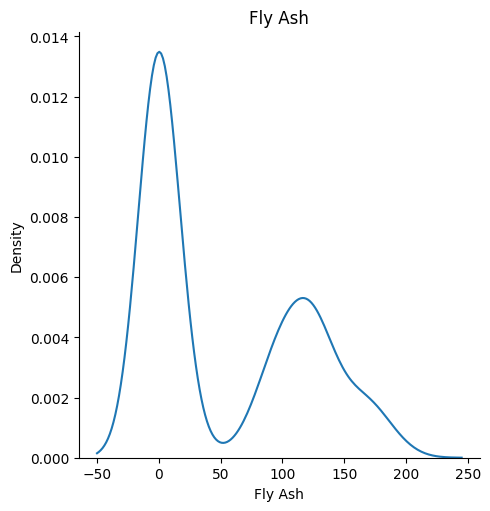

<Figure size 1400x400 with 0 Axes>

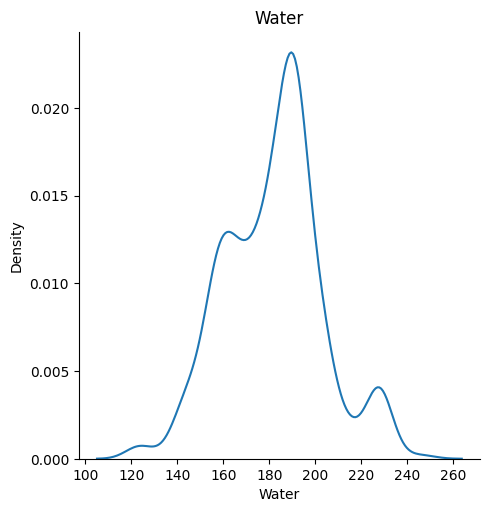

<Figure size 1400x400 with 0 Axes>

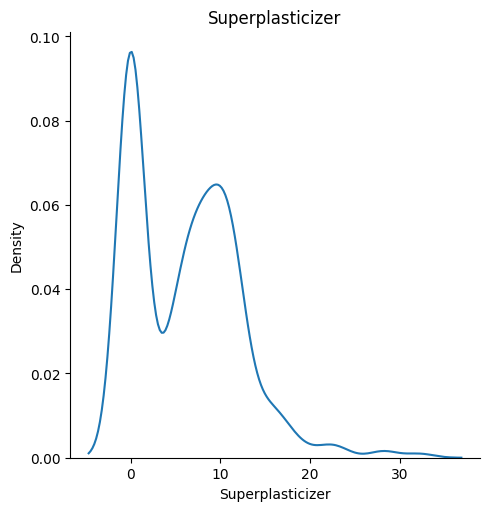

<Figure size 1400x400 with 0 Axes>

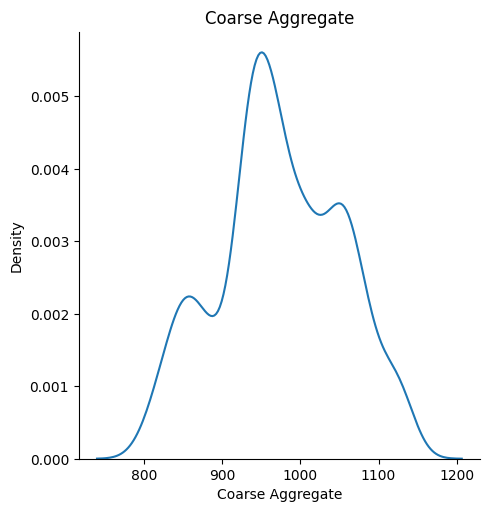

<Figure size 1400x400 with 0 Axes>

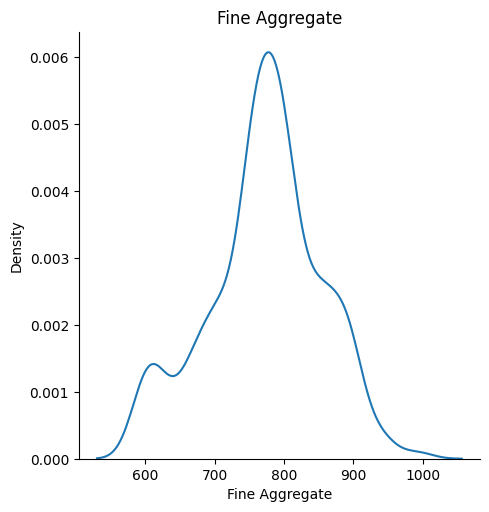

<Figure size 1400x400 with 0 Axes>

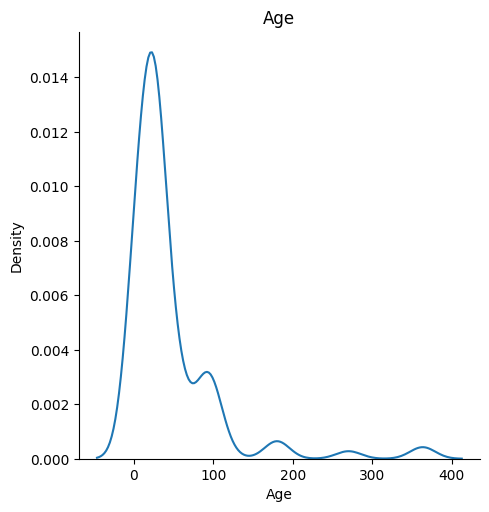

In [19]:
for col in X_train.columns:
    plt.figure(figsize=(14,4))
    sns.displot(X_train[col], kind='kde')
    plt.title(col)
    plt.show()

In [20]:
pt = PowerTransformer(method='box-cox')

In [21]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(824, 8)
(206, 8)
(824,)
(206,)


In [22]:
X_train_trf = pt.fit_transform(X_train+0.000001)
X_test_trf = pt.transform(X_test+0.000001)

In [26]:
print(X_test_trf.shape)
print(X_train_trf.shape)

(206, 8)
(824, 8)


In [24]:
pd.DataFrame({'cols':X_train.columns, 'box_cox_lambdas':pt.lambdas_})

,cols,box_cox_lambdas
0,Cement,0.177025
1,Blast Furnace Slag,0.025093
2,Fly Ash,-0.038970
3,Water,0.772682
4,Superplasticizer,0.098811
5,Coarse Aggregate,1.129813
6,Fine Aggregate,1.782018
7,Age,0.066631


In [27]:
lr2=LinearRegression()
lr2.fit(X_train_trf,y_train)

LinearRegression()

In [28]:
y_pred2 = lr2.predict(X_test_trf)

In [29]:
r2_score(y_test,y_pred2)

0.8047825005397711

In [32]:
np.mean(cross_val_score(lr2,X_train_trf,y_train, scoring='r2', cv=10))

0.7914577089883774

In [33]:
pt1 = PowerTransformer()
X_train_trf2 = pt1.fit_transform(X_train)
X_test_trf2 = pt1.transform(X_test)
lr2=LinearRegression()

In [34]:
lr2.fit(X_train_trf2,y_train)

LinearRegression()

In [35]:
y_pred3 = lr2.predict(X_test_trf2)

In [36]:
r2_score(y_test, y_pred3)

0.8161906513339307

In [44]:
np.mean(cross_val_score(lr2,X_train_trf2,y_train, scoring='r2', cv=10))

0.7936885678909091